# Análise Exploratória: Corpus de Editais de Leilão de Imóveis (SP)

**Disciplina:** Inteligência Artificial, FCI / Universidade Presbiteriana Mackenzie
**Opção do projeto:** API de LLM (análise de documentos)
**Projeto:** Assistente de leitura de editais de leilão para pessoas leigas

**Integrantes:**
- Luiz Eduardo Bacha dos Santos (RA 10425296) - 10425296@mackenzista.com.br
- Guilherme Haddad Borro (RA 10427699) - 10427699@mackenzista.com.br

**Síntese do arquivo:** carrega o `metadata.csv` do corpus de editais coletado
(`src/coletar_editais.py`), faz a análise exploratória e a preparação dos dados
que alimentam a solução baseada em LLM.

**Histórico de alterações:**
| Data | Autor | Descrição |
|------|-------|-----------|
| 2026-09-13 | Guilherme Haddad Borro | criação da EDA (carga, estatísticas, gráficos, preparação) |
| 2026-09-13 | Luiz Eduardo Bacha dos Santos | revisão do cabeçalho e dos integrantes |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
FIG = Path("..") / "figuras"; FIG.mkdir(exist_ok=True)

df = pd.read_csv(Path("..") / "dataset" / "metadata.csv")
print("Dimensão:", df.shape)
df.head()

Dimensão: (87, 27)


,lote_id,leilao_id,bairro,area_m2,ocupacao,valor_avaliacao,tem_sql_cadastral,tem_edital,tem_matricula,edital_paginas,...,termo_penhora,termo_usufruto,termo_alienacao_fiduciaria,termo_iptu,termo_condominio,termo_divida_ativa,termo_financiamento,termo_comissao_leiloeiro,termo_debito,termo_ocupado
0,128917,34704.0,Paulista Bela Vista,75.0,Não informado,NaN,False,True,True,58,...,True,False,True,True,True,True,True,True,True,True
1,128923,34704.0,Vagas Morumbi,240.0,Não informado,NaN,False,True,True,58,...,True,False,True,True,True,True,True,True,True,True
2,128870,34704.0,Vaga Vila Matilde,79.0,Não informado,NaN,False,True,True,58,...,True,False,True,True,True,True,True,True,True,True
3,128879,34704.0,Alto Da Mooca,132.0,Não informado,NaN,False,True,True,58,...,True,False,True,True,True,True,True,True,True,True
4,128882,34704.0,Vaga Pirituba,60.0,Não informado,NaN,False,True,True,58,...,True,False,True,True,True,True,True,True,True,True


## 1. Visão geral e tipos de dados

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   lote_id                     87 non-null     str    
 1   leilao_id                   28 non-null     float64
 2   bairro                      87 non-null     str    
 3   area_m2                     80 non-null     float64
 4   ocupacao                    87 non-null     str    
 5   valor_avaliacao             0 non-null      float64
 6   tem_sql_cadastral           87 non-null     bool   
 7   tem_edital                  87 non-null     bool   
 8   tem_matricula               87 non-null     bool   
 9   edital_paginas              87 non-null     int64  
 10  edital_chars                87 non-null     int64  
 11  matricula_paginas           87 non-null     int64  
 12  matricula_chars             87 non-null     int64  
 13  tipo_leilao                 87 non-null     str 

In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
lote_id,87,87,128917,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
leilao_id,28.0,NaN,NaN,NaN,34701.464286,60.438816,34455.0,34704.0,34704.0,34739.0,34758.0
bairro,87,32,São Paulo,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_m2,80.0,NaN,NaN,NaN,84.0875,73.309677,23.0,43.0,57.5,85.75,487.0
ocupacao,87,3,Não informado,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
valor_avaliacao,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tem_sql_cadastral,87,2,True,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tem_edital,87,1,True,87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tem_matricula,87,2,True,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edital_paginas,87.0,NaN,NaN,NaN,14.689655,19.488405,1.0,3.0,5.0,13.5,58.0


## 2. Qualidade dos dados — valores ausentes

Como a fonte são documentos (PDFs) de origens diferentes, a ausência de campos é
esperada (nem todo lote tem matrícula anexada, nem todo edital informa avaliação).

% de valores ausentes por coluna:
valor_avaliacao    100.0
leilao_id           67.8
area_m2              8.0
dtype: float64


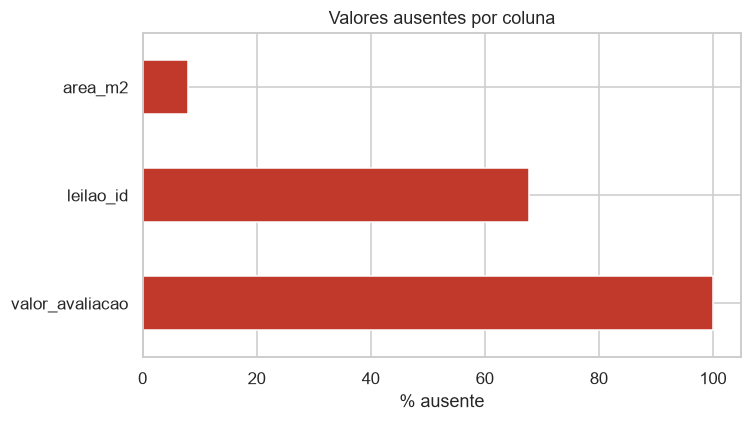

In [4]:
faltantes = df.isna().mean().sort_values(ascending=False) * 100
faltantes = faltantes[faltantes > 0]
print("% de valores ausentes por coluna:")
print(faltantes.round(1))
ax = faltantes.plot(kind="barh", color="#c0392b", figsize=(7,4))
ax.set_xlabel("% ausente"); ax.set_title("Valores ausentes por coluna")
plt.tight_layout(); plt.savefig(FIG/"01_ausentes.png"); plt.show()

## 3. Estrutura do corpus — lotes x editais

O **edital** é um documento por *leilão* (compartilhado por vários lotes); a
**matrícula** é por *lote*. Medir a razão lote/edital mostra o quanto o corpus é
redundante em nível de edital.

Lotes: 87
Editais únicos (leilões): 66
Média de lotes por edital: 1.3
Lotes com edital: 100%
Lotes com matrícula: 99%


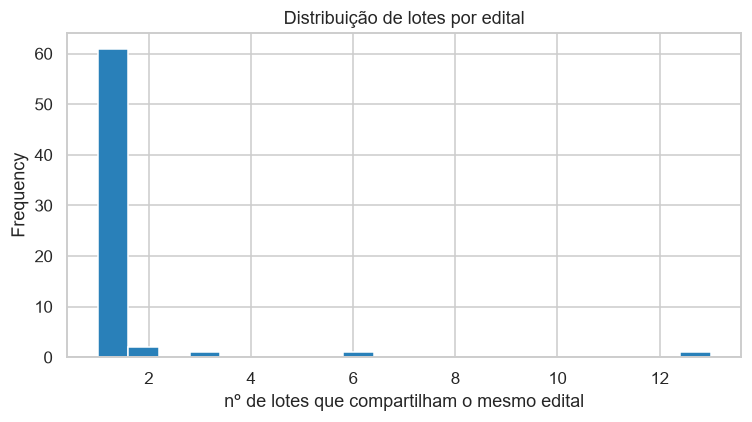

In [5]:
n_lotes = len(df)
n_editais = df["edital_url"].nunique()
print(f"Lotes: {n_lotes}")
print(f"Editais únicos (leilões): {n_editais}")
print(f"Média de lotes por edital: {n_lotes / max(n_editais,1):.1f}")
print(f"Lotes com edital: {df['tem_edital'].mean()*100:.0f}%")
print(f"Lotes com matrícula: {df['tem_matricula'].mean()*100:.0f}%")

lotes_por_edital = df.groupby("edital_url").size()
ax = lotes_por_edital.plot(kind="hist", bins=20, color="#2980b9", figsize=(7,4))
ax.set_xlabel("nº de lotes que compartilham o mesmo edital")
ax.set_title("Distribuição de lotes por edital")
plt.tight_layout(); plt.savefig(FIG/"02_lotes_por_edital.png"); plt.show()

## 4. Tamanho dos documentos (páginas e caracteres)

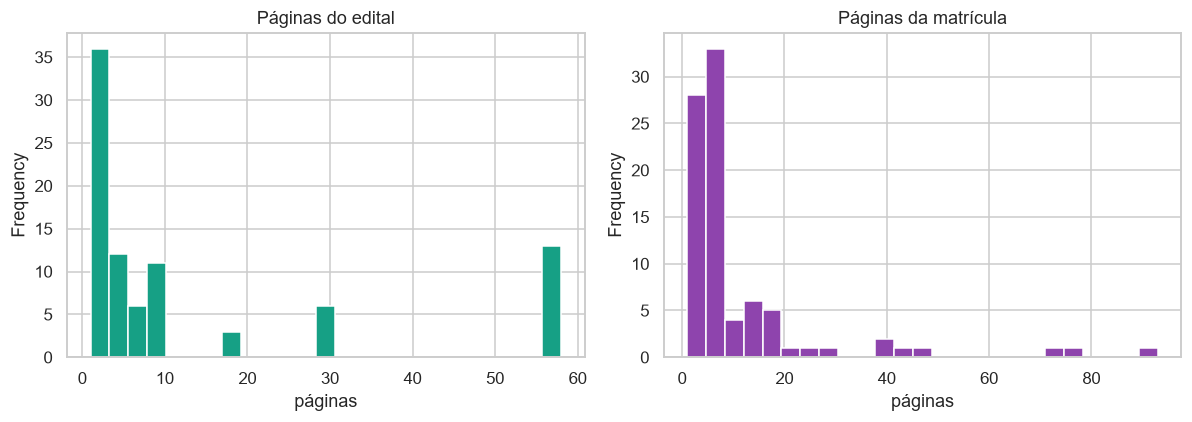

Edital — páginas:   {'count': 87.0, 'mean': 14.7, 'std': 19.5, 'min': 1.0, '25%': 3.0, '50%': 5.0, '75%': 13.5, 'max': 58.0}
Edital — caracteres: {'count': 87.0, 'mean': 45275.0, 'std': 61142.0, 'min': 2033.0, '25%': 8327.0, '50%': 16309.0, '75%': 46992.0, 'max': 183901.0}


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11,4))
df[df.edital_paginas>0]["edital_paginas"].plot(kind="hist", bins=25, ax=axs[0], color="#16a085")
axs[0].set_title("Páginas do edital"); axs[0].set_xlabel("páginas")
df[df.matricula_paginas>0]["matricula_paginas"].plot(kind="hist", bins=25, ax=axs[1], color="#8e44ad")
axs[1].set_title("Páginas da matrícula"); axs[1].set_xlabel("páginas")
plt.tight_layout(); plt.savefig(FIG/"03_paginas.png"); plt.show()

print("Edital — páginas:  ", df[df.edital_paginas>0]["edital_paginas"].describe().round(1).to_dict())
print("Edital — caracteres:", df[df.edital_chars>0]["edital_chars"].describe().round(0).to_dict())

Esse é o **cerne da justificativa do projeto**: o edital mediano tem dezenas de
páginas de texto jurídico — inviável de ler para o arrematante leigo.

## 5. Variáveis categóricas — tipo de leilão e ocupação

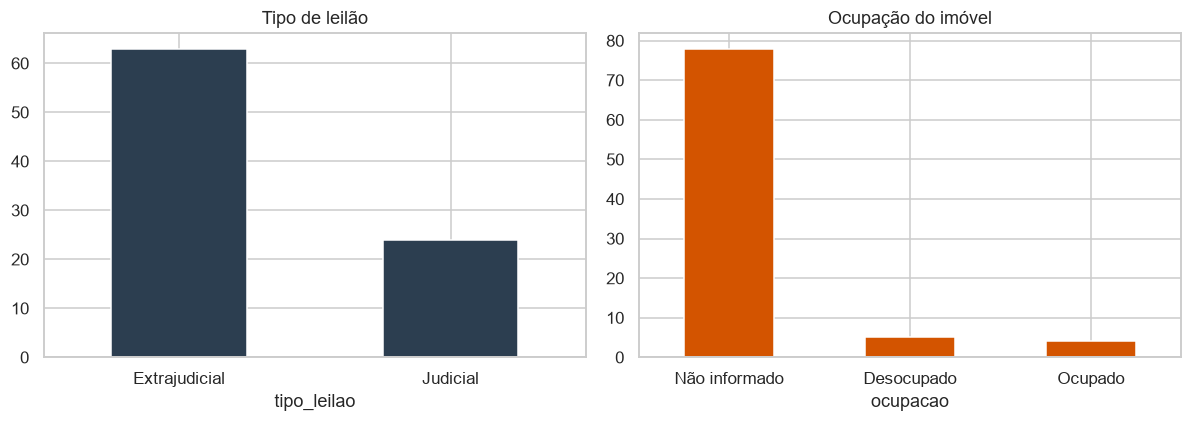

tipo_leilao
Extrajudicial    72.4
Judicial         27.6
Name: proportion, dtype: float64
ocupacao
Não informado    89.7
Desocupado        5.7
Ocupado           4.6
Name: proportion, dtype: float64


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11,4))
df["tipo_leilao"].value_counts().plot(kind="bar", ax=axs[0], color="#2c3e50")
axs[0].set_title("Tipo de leilão"); axs[0].tick_params(axis='x', rotation=0)
df["ocupacao"].value_counts().plot(kind="bar", ax=axs[1], color="#d35400")
axs[1].set_title("Ocupação do imóvel"); axs[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(FIG/"04_categoricas.png"); plt.show()
print(df["tipo_leilao"].value_counts(normalize=True).mul(100).round(1))
print(df["ocupacao"].value_counts(normalize=True).mul(100).round(1))

## 6. Variáveis numéricas — área e valor de avaliação

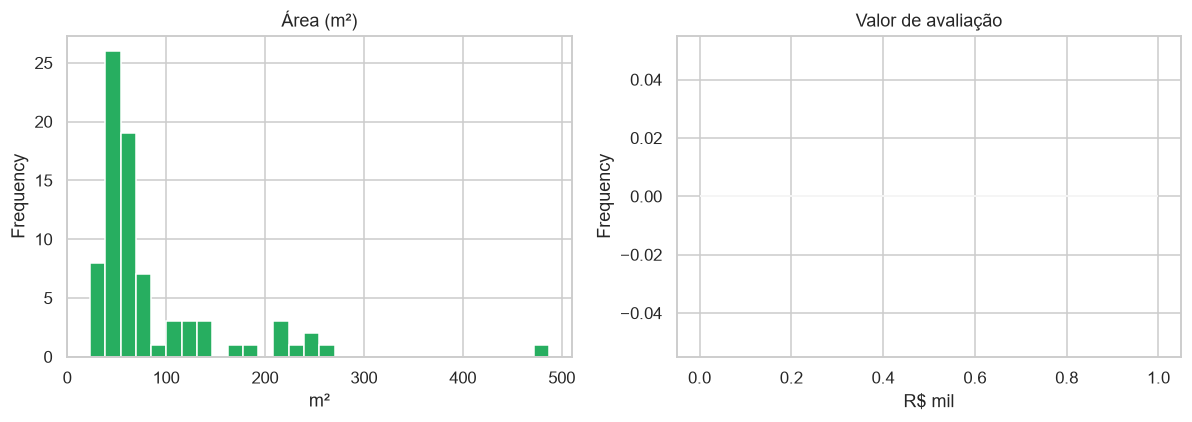

Área m²: {'count': 80.0, 'mean': 84.1, 'std': 73.3, 'min': 23.0, '25%': 43.0, '50%': 57.5, '75%': 85.8, 'max': 487.0}
Avaliação R$: {'count': 0.0, 'mean': nan, 'std': nan, 'min': nan, '25%': nan, '50%': nan, '75%': nan, 'max': nan}


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11,4))
df["area_m2"].dropna().plot(kind="hist", bins=30, ax=axs[0], color="#27ae60")
axs[0].set_title("Área (m²)"); axs[0].set_xlabel("m²")
val = df["valor_avaliacao"].dropna()
(val/1000).plot(kind="hist", bins=30, ax=axs[1], color="#c0392b")
axs[1].set_title("Valor de avaliação"); axs[1].set_xlabel("R$ mil")
plt.tight_layout(); plt.savefig(FIG/"05_numericas.png"); plt.show()
print("Área m²:", df["area_m2"].describe().round(1).to_dict())
print("Avaliação R$:", val.describe().round(0).to_dict())

## 7. Caracterização jurídica do corpus — termos de risco

Frequência de termos jurídicos/técnicos nos editais. Motiva o **glossário
automático** e a **classificação de risco** feitos pela LLM: são justamente esses
termos que o leigo não entende.

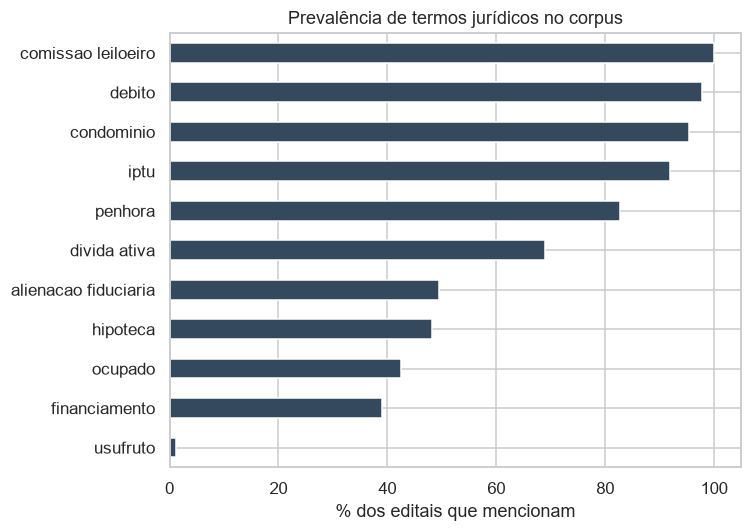

usufruto                  1.1
financiamento            39.1
ocupado                  42.5
hipoteca                 48.3
alienacao fiduciaria     49.4
divida ativa             69.0
penhora                  82.8
iptu                     92.0
condominio               95.4
debito                   97.7
comissao leiloeiro      100.0
dtype: float64

In [9]:
termos = [c for c in df.columns if c.startswith("termo_")]
prev = (df[df.tem_edital][termos].mean().sort_values() * 100)
prev.index = [t.replace("termo_", "").replace("_", " ") for t in prev.index]
ax = prev.plot(kind="barh", color="#34495e", figsize=(7,5))
ax.set_xlabel("% dos editais que mencionam"); ax.set_title("Prevalência de termos jurídicos no corpus")
plt.tight_layout(); plt.savefig(FIG/"06_termos.png"); plt.show()
prev.round(1)

## 8. Relação entre variáveis — ocupação x tipo de leilão

ocupacao       Desocupado  Não informado  Ocupado
tipo_leilao                                      
Extrajudicial         7.9           85.7      6.3
Judicial              0.0          100.0      0.0


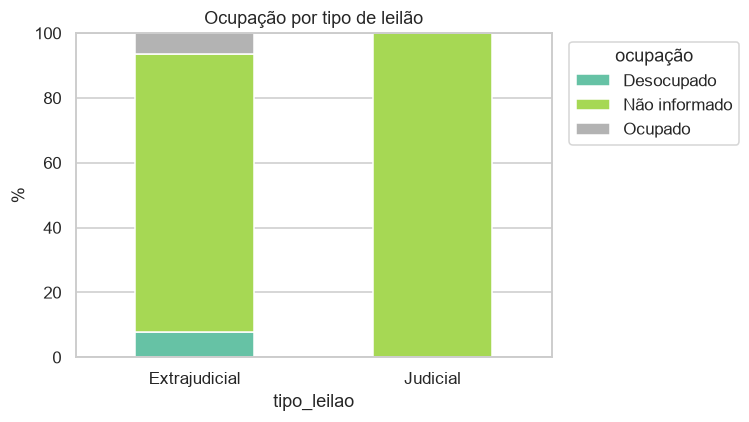

In [10]:
ct = pd.crosstab(df["tipo_leilao"], df["ocupacao"], normalize="index").mul(100).round(1)
print(ct)
ax = ct.plot(kind="bar", stacked=True, figsize=(7,4), colormap="Set2")
ax.set_ylabel("%"); ax.set_title("Ocupação por tipo de leilão"); ax.tick_params(axis='x', rotation=0)
plt.legend(title="ocupação", bbox_to_anchor=(1.02,1))
plt.tight_layout(); plt.savefig(FIG/"07_ocupacao_x_tipo.png"); plt.show()

## 9. Preparação dos dados

Passos aplicados para deixar o corpus pronto para a solução com LLM:
1. remover lotes **sem edital** (não há documento a analisar);
2. derivar `tem_texto` (extração de PDF bem-sucedida) e `porte_edital` (faixas de tamanho);
3. persistir o dataset limpo em `dataset/dataset_preparado.csv`.

In [11]:
limpo = df[df.tem_edital & (df.edital_chars > 0)].copy()
limpo["porte_edital"] = pd.cut(limpo["edital_paginas"],
                               bins=[0,20,40,60,10_000],
                               labels=["curto (<=20p)","médio (21-40p)","longo (41-60p)","muito longo (>60p)"])
print("Lotes analisáveis:", len(limpo), "de", len(df))
print(limpo["porte_edital"].value_counts())
limpo.to_csv(Path("..")/"dataset"/"dataset_preparado.csv", index=False)
print("Salvo: dataset/dataset_preparado.csv")

Lotes analisáveis: 87 de 87
porte_edital
curto (<=20p)         68
longo (41-60p)        13
médio (21-40p)         6
muito longo (>60p)     0
Name: count, dtype: int64
Salvo: dataset/dataset_preparado.csv


## 10. Síntese da EDA

- O corpus concentra editais **extrajudiciais** longos (dezenas de páginas), o que
  confirma o problema: leitura inviável para o arrematante leigo.
- Termos como *alienação fiduciária*, *hipoteca*, *penhora*, *IPTU* e *condomínio*
  aparecem na maioria dos editais — justificando o **glossário** e a **extração de
  débitos/ônus** feitos pela LLM.
- A taxa alta de imóveis **ocupados** reforça a necessidade de sinalizar risco de
  desocupação.
- Dados ausentes (avaliação, matrícula) são tratados: o pipeline degrada com
  elegância quando um documento não está presente.

Esses achados definem os campos que a LLM deve extrair de cada edital na fase de
desenvolvimento (N2).